# Check convergence 

In [1]:
import cobra
import pandas as pd
import numpy as np
from os import listdir
import warnings
import seaborn as sns
from collections import OrderedDict
import json
import os
import matplotlib.pyplot as plt
import math



from reframed.community.model import Community
from reframed import Environment, set_default_solver
from steadiercom.cli import load_communities,load_media_db

In [2]:
import seaborn as sns

In [3]:
import sys

sys.path.append("../functions/")
from convergence import SteadierSampleConvergence

In [4]:
%load_ext autoreload
%autoreload 2

In [5]:
communities_no_abundance = pd.read_csv("../../SteadierCom/tests/data/communities1.tsv",sep="\t",header=None)
communities_no_abundance

,0,1,2
0,test,ec_glc_ko,0.3
1,test,ec_nh4_ko,0.7


In [6]:
communities_no_abundance.drop(2,axis=1).to_csv("../../SteadierCom/tests/data/communities_no_abundance.tsv",sep="\t",header=None,index=None)


### Gut microbiome community

Concentration $X_0$ (right after serial transfer) and $X_1$ (right before next transfer) in $t_0$ and $t_1$

$$
X_1 = X_0 *e^{\mu t_1} , X_0 = X_0
$$

Assuming that the cells grow back to the original concentration (after being diluted 1:20 => the cells increase in density by 21 times)

$$
X_1/X_0 = 21 = e^{\mu t} 
$$

The above equation turns into:
$$
ln(X_1/X_0) = \mu t
$$

Which means the avearage growth rate becomes
$$
\mu_{avg} = \frac{ln(21)}{t}
$$

**Methods (From Venturelli et al. 2018): 1:20 dilution every 24 h**

In [7]:
np.log(20)/24

np.float64(0.12482217806474961)

In [8]:
mediadb = "../data/Venturelli2018/generated/media_db.tsv"#path to mediadb
medium = "LB_extend"
growth = np.log(20)/24# average growth rate

models = ["../models/Venturelli2018/species_used/"+name for name in listdir("../models/Venturelli2018/species_used_noO2/")]
communities = "../data/Venturelli2018/generated/communities_steadiercom/NONE_abundance.tsv"

comm_id = "NONE"

output_dir = "../output/Venturelli2018/convergence_test/"

In [9]:
%%time

abstol = 1e-6
model_cache, comm_dict, has_abundance = load_communities(models, communities, exchange_detection='R_EX_(?!biomass__40__e__41__)')

media_db, media_has_bounds = load_media_db(mediadb)
results = []

organisms = comm_dict[comm_id]

abundance = organisms
organisms = organisms.keys()
comm_models = [model_cache.get_model(org_id, reset_id=True) for org_id in organisms]
community = Community(comm_id, comm_models, copy_models=False)

env = Environment.from_reactions(media_db[medium],max_uptake=10)
env.apply(community.merged_model, inplace=False, exclusive=True, warning=False)
env_dict = dict(env)

print(f'simulating {comm_id} in {medium} medium')

sol_df = SteadierSampleConvergence(community,output_dir=output_dir,n=20001, abundance=abundance, growth=growth, allocation=True, constraints=env)

/Users/idunmariaburgos/SteadierCom/reframed/reframed/io/sbml.py:579: UserWarning: Could not extract annotation from http://identifiers.org/inchi/InChI=1S/C12H21N3O13P2/c13-8-1-2-15(12(20)14-8)11-10(19)9(18)7(27-11)5-26-30(23,24)28-29(21,22)25-4-6(17)3-16/h1-2,6-7,9-11,16-19H,3-5H2,(H,21,22)(H,23,24)(H2,13,14,20)/
  warn(f'Could not extract annotation from {term.getResourceURI(i)}')
/Users/idunmariaburgos/SteadierCom/reframed/reframed/io/sbml.py:579: UserWarning: Could not extract annotation from http://identifiers.org/inchi/InChI=1S/C11H12Cl2N2O5/c12-10(13)11(18)14-8(5-16)9(17)6-1-3-7(4-2-6)15(19)20/h1-4,8-10,16-17H,5H2,(H,14,18)/
  warn(f'Could not extract annotation from {term.getResourceURI(i)}')
/Users/idunmariaburgos/SteadierCom/reframed/reframed/io/sbml.py:579: UserWarning: Could not extract annotation from http://identifiers.org/inchi/InChI=1S/C15H26N2O12/c1-4(20)16-7-11(23)12(6(3-19)27-13(7)24)29-14-8(17-15(25)26)10(22)9(21)5(2-18)28-14/h5-14,17-19,21-24H,2-3H2,1H3,(H,16,20)(H,

simulating NONE in LB_extend medium
Set parameter Username
Academic license - for non-commercial use only - expires 2026-03-27


/Users/idunmariaburgos/SteadierCom/reframed/reframed/solvers/gurobi_solver.py:133: UserWarning: Constrained variable 'R_EX_thym__91__e__93__' not previously declared
  warn(f"Constrained variable '{r_id}' not previously declared")
/Users/idunmariaburgos/SteadierCom/reframed/reframed/solvers/gurobi_solver.py:133: UserWarning: Constrained variable 'R_EX_pydxn_R__91__e__93__' not previously declared
  warn(f"Constrained variable '{r_id}' not previously declared")


Round 200. Time passed: 1.00 minutes


/Users/idunmariaburgos/SteadierCom/reframed/reframed/solvers/gurobi_solver.py:133: UserWarning: Constrained variable 'R_EX_thym__91__e__93__' not previously declared
  warn(f"Constrained variable '{r_id}' not previously declared")
/Users/idunmariaburgos/SteadierCom/reframed/reframed/solvers/gurobi_solver.py:133: UserWarning: Constrained variable 'R_EX_pydxn_R__91__e__93__' not previously declared
  warn(f"Constrained variable '{r_id}' not previously declared")
Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x11152cb20>>
Traceback (most recent call last):
  File "/Users/idunmariaburgos/opt/anaconda3/envs/steadiercom/lib/python3.10/site-packages/ipykernel/ipkernel.py", line 775, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(
KeyboardInterrupt: 
Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x11152cb20>>
Traceback

KeyboardInterrupt: 

In [10]:
direct = os.listdir("../output/Venturelli2018/convergence_test/")

dfs = []
for d in direct:
    if d.endswith(".tsv"):
        df = pd.read_csv("../output/Venturelli2018/convergence_test/"+str(d),sep="\t",index_col=(0,1))
        dfs.append(df)

dfs_tot = pd.concat(dfs,axis=1)

dfs_tot = dfs_tot.T.drop_duplicates().T

dfs_tot.columns = np.arange(0,dfs_tot.shape[1])
dfs_tot = dfs_tot.fillna(0) # fills values with 


### Plotting coefficient of variance based on sample size

The x-axis shows the number of samples in each set. The y-axis shows the coefficient of variance across all sets of the same size. We expect a higher number of samples in each set to cover more alternative optima and thereby reduce the variance between sets.

We see that there is lower variance between sets when their sample size is large.

In [78]:
base = 10
sample_sizes = [base * int(1.5**i) for i in range(18)] 
sample_sizes = [s for s in sample_sizes if s<10000]

datas = {}
for n in sample_sizes:
    sample_size = int(n)

    number = math.floor(dfs_tot.shape[1]/sample_size)
    data = pd.DataFrame.from_dict({f"set{i}":dfs_tot[np.arange(0+i*sample_size,(i+1)*sample_size)].T.mean() for i in np.arange(0,number)})


    equal_zero= data.sum(axis=1).apply(abs).sort_values() <1e-3 #Cutoff set to same value as for the gut microbiome
    data = data.loc[~equal_zero]
    
    cv = lambda x: np.std(x, ddof=1) / abs(np.mean(x)) * 100 
    data = data.T.apply(cv)
    datas[sample_size]=data    


sample_sizes_higher_res = np.arange(2000,11000,1000)

datas_higher_res = {}
for n in sample_sizes_higher_res:
    sample_size = int(n)

    number = math.floor(dfs_tot.shape[1]/sample_size)
    data = pd.DataFrame.from_dict({f"set{i}":dfs_tot[np.arange(0+i*sample_size,(i+1)*sample_size)].T.mean() for i in np.arange(0,number)})


    equal_zero= data.sum(axis=1).apply(abs).sort_values() <1e-3 #Cutoff set to same value as for the gut microbiome
    data = data.loc[~equal_zero]
    
    cv = lambda x: np.std(x, ddof=1) / abs(np.mean(x)) * 100 
    data = data.T.apply(cv)
    datas_higher_res[sample_size]=data 

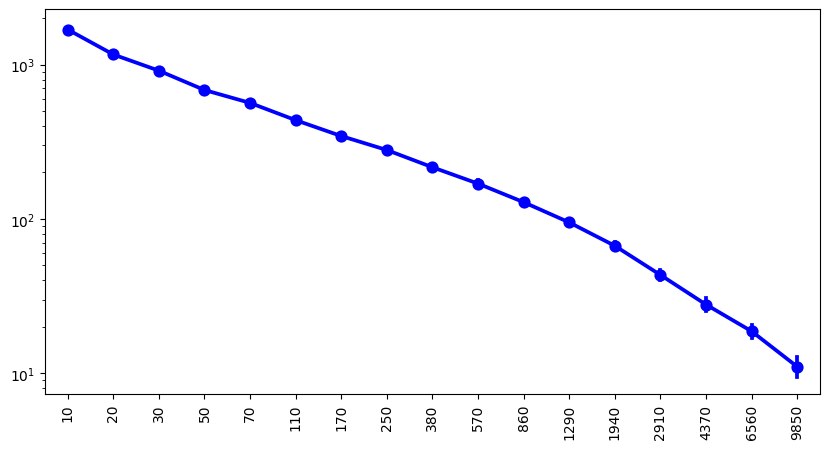

In [79]:
fig = plt.figure(figsize =(10, 5))
ax = fig.add_subplot(111)
ax = sns.pointplot(pd.DataFrame(datas),ax=ax, color="blue")
ticks = plt.xticks(rotation=90)
plt.yscale('log')

(0.0, 100.0)

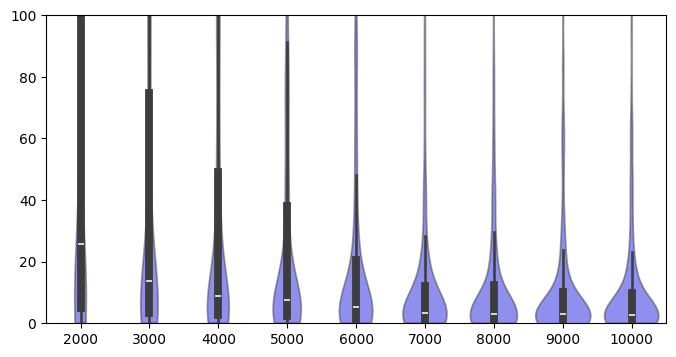

In [80]:
fig = plt.figure(figsize =(8, 4))
ax = fig.add_subplot(111)
ax = sns.violinplot(pd.DataFrame(datas_higher_res),cut=0,ax=ax,color="blue",alpha=0.5)
ax.set_ylim([0,100])

In [81]:
pd.DataFrame(datas_higher_res).median()

2000     25.743563
3000     13.692172
4000      8.964625
5000      7.404214
6000      5.259508
7000      3.380397
8000      3.154538
9000      3.107057
10000     2.678183
dtype: float64

### Plotting coefficient of variance based on average flux rate and sample size

The x-axis represent the range of average flux rate across different sets (example: flux is between 1e-6 and 3e-6). The y-axis represents the coefficient of variance. 

We see that when the average flux is higher the coefficient of variance is lower.

In [49]:
statistics = {}

for n in sample_sizes:
    b = -6
    
    statistics[n]={}
    for a in np.linspace(-5.5,1,14):

        sample_size = int(n)
        number = math.floor(dfs_tot.shape[1]/sample_size)


        data = pd.DataFrame.from_dict({f"set{i}":dfs_tot[np.arange(0+i*sample_size,(i+1)*sample_size)].T.mean() for i in np.arange(0,number)})

        data_set_lower= data.mean(axis=1).apply(abs).sort_values() <10**(a)
        data_set_upper = data.mean(axis=1).apply(abs).sort_values() >10**(b)
        data_bound = data_set_lower * data_set_upper
        data = data.loc[data_bound]

        cv = lambda x: np.std(x, ddof=1) / abs(np.mean(x)) * 100 
        data = data.T.apply(cv)


        median = data.median()

        statistics[n][(round(10**b,6),round(10**a,6))] =median
        b=a
        
        
statistics_higher_res = {}
for n in sample_sizes_higher_res:
    b = -6
    
    statistics_higher_res[n]={}
    for a in np.linspace(-5.5,1,14):

        sample_size = int(n)
        number = math.floor(dfs_tot.shape[1]/sample_size)


        data = pd.DataFrame.from_dict({f"set{i}":dfs_tot[np.arange(0+i*sample_size,(i+1)*sample_size)].T.mean() for i in np.arange(0,number)})

        data_set_lower= data.mean(axis=1).apply(abs).sort_values() <10**(a)
        data_set_upper = data.mean(axis=1).apply(abs).sort_values() >10**(b)
        data_bound = data_set_lower * data_set_upper
        data = data.loc[data_bound]

        cv = lambda x: np.std(x, ddof=1) / abs(np.mean(x)) * 100 
        data = data.T.apply(cv)


        median = data.median()

        statistics_higher_res[n][(round(10**b,6),round(10**a,6))] =median
        b=a

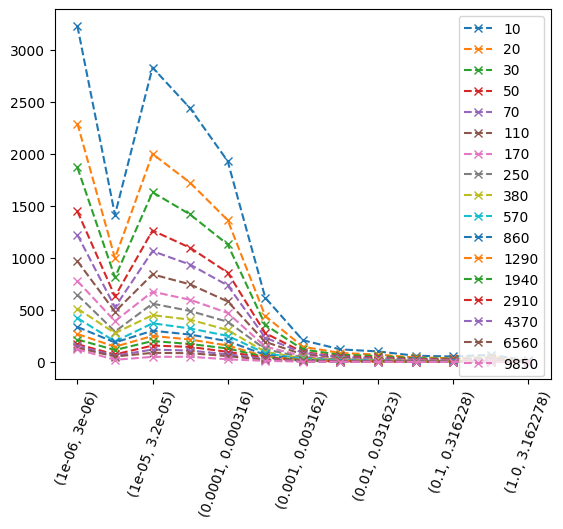

In [50]:
pd.DataFrame(statistics).plot(marker="x",linestyle="--")
xticks = plt.xticks(rotation=70)

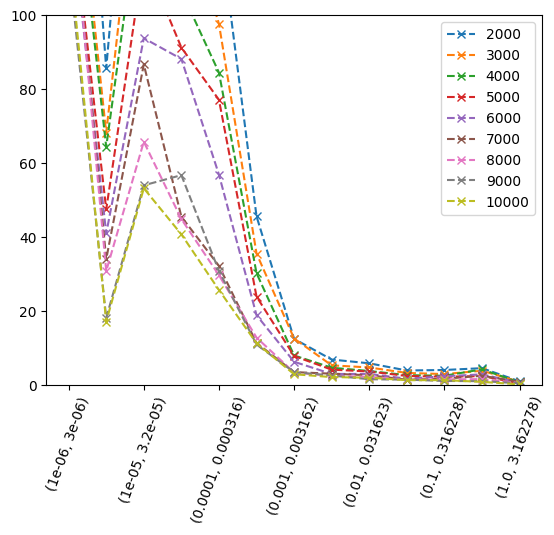

In [51]:
pd.DataFrame(statistics_higher_res).plot(marker="x",linestyle="--",ylim=[0,100])
xticks = plt.xticks(rotation=70)

## E.coli mutants community

Concentration $X_0$ (right after serial transfer) and $X_1$ (right before next transfer) in $t_0$ and $t_1$

$$
X_1 = X_0 *e^{\mu t_1} , X_0 = X_0
$$

Assuming that the cells grow back to the original concentration (after being diluted 5:995 => has to increase 200 times)

$$
X_1/X_0 = 200 = e^{\mu t} 
$$

The above equation turns into:
$$
ln(X_1/X_0) = \mu t
$$

Which means the avearage growth rate becomes
$$
\mu_{avg} = \frac{ln(200)}{t}
$$

**Methods (From Guillen et al. 2021): 1:200 dilution every 24 h**

In [52]:
np.log(200)/24

np.float64(0.22076322360616818)

**Input data**

In [62]:
mediadb = "../data/Guillen2021/generated/media_db.tsv"#path to mediadb
media = ["M9"]
growth = np.log(200)/24 

models = ["../models/Guillen2021/top_7_strains/"+name for name in listdir("../models/Guillen2021/top_7_strains/")]
communities = "../data/Guillen2021/generated/communities_steadiercom.tsv"

comm_id = "Ecoli_mutants"

output_dir = "../output/Guillen2021/convergence_test/"

**Run SteadierSample**

**Load SteadierSample results**

In [63]:
direct = os.listdir("../output/Guillen2021/convergence_test/")

dfs = []
for d in direct:
    if d.endswith(".tsv"):
        df = pd.read_csv("../output/Guillen2021/convergence_test/"+str(d),sep="\t",index_col=(0,1))
        dfs.append(df)

dfs_tot = pd.concat(dfs,axis=1)

dfs_tot = dfs_tot.T.drop_duplicates().T

dfs_tot.columns = np.arange(0,dfs_tot.shape[1])
dfs_tot = dfs_tot.fillna(0)


### Plotting coefficient of variance based on sample size

The x-axis shows the number of samples in each set. The y-axis shows the coefficient of variance across all sets of the same size. We expect a higher number of samples in each set to cover more alternative optima and thereby reduce the variance between sets.

We see that there is lower variance between sets when their sample size is large.

In [68]:
base = 10
sample_sizes = [base * int(1.5**i) for i in range(18)] 
sample_sizes = [s for s in sample_sizes if s<10000]

datas = {}
for n in sample_sizes:
    sample_size = int(n)

    number = math.floor(dfs_tot.shape[1]/sample_size)
    data = pd.DataFrame.from_dict({f"set{i}":dfs_tot[np.arange(0+i*sample_size,(i+1)*sample_size)].T.mean() for i in np.arange(0,number)})


    equal_zero= data.sum(axis=1).apply(abs).sort_values() <1e-3 #Cutoff set to same value as for the gut microbiome
    data = data.loc[~equal_zero]
    
    cv = lambda x: np.std(x, ddof=1) / abs(np.mean(x)) * 100 
    data = data.T.apply(cv)
    datas[sample_size]=data    


sample_sizes_higher_res = np.arange(2000,11000,1000)

datas_higher_res = {}
for n in sample_sizes_higher_res:
    sample_size = int(n)

    number = math.floor(dfs_tot.shape[1]/sample_size)
    data = pd.DataFrame.from_dict({f"set{i}":dfs_tot[np.arange(0+i*sample_size,(i+1)*sample_size)].T.mean() for i in np.arange(0,number)})


    equal_zero= data.sum(axis=1).apply(abs).sort_values() <1e-3 #Cutoff set to same value as for the gut microbiome
    data = data.loc[~equal_zero]
    
    cv = lambda x: np.std(x, ddof=1) / abs(np.mean(x)) * 100 
    data = data.T.apply(cv)
    datas_higher_res[sample_size]=data 

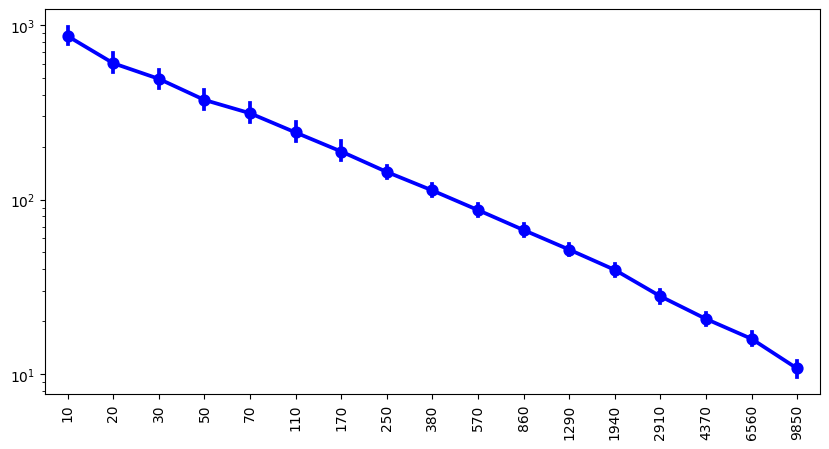

In [69]:
fig = plt.figure(figsize =(10, 5))
ax = fig.add_subplot(111)
ax = sns.pointplot(pd.DataFrame(datas),ax=ax, color="blue")
ticks = plt.xticks(rotation=90)

plt.yscale('log')

(0.0, 100.0)

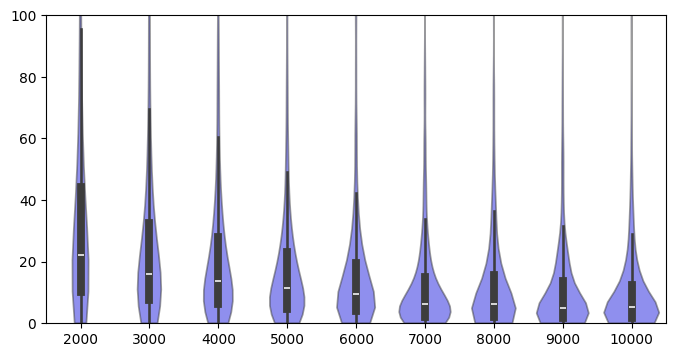

In [70]:
fig = plt.figure(figsize =(8, 4))
ax = fig.add_subplot(111)
ax = sns.violinplot(pd.DataFrame(datas_higher_res),cut=0,ax=ax,color="blue",alpha=0.5)
ax.set_ylim([0,100])

In [73]:
pd.DataFrame(datas_higher_res).median()

2000     22.119228
3000     16.148047
4000     13.785391
5000     11.298863
6000      9.463287
7000      6.418155
8000      6.169898
9000      4.929857
10000     5.317447
dtype: float64

### Plotting coefficient of variance based on average flux rate and sample size

The x-axis represent the range of average flux rate across different sets (example: flux is between 1e-6 and 3e-6). The y-axis represents the coefficient of variance. 

We see that when the average flux is higher the coefficient of variance is lower.

In [74]:
statistics = {}

for n in sample_sizes:
    b = -6
    
    statistics[n]={}
    for a in np.linspace(-5.5,1,14):

        sample_size = int(n)
        number = math.floor(dfs_tot.shape[1]/sample_size)


        data = pd.DataFrame.from_dict({f"set{i}":dfs_tot[np.arange(0+i*sample_size,(i+1)*sample_size)].T.mean() for i in np.arange(0,number)})

        data_set_lower= data.mean(axis=1).apply(abs).sort_values() <10**(a)
        data_set_upper = data.mean(axis=1).apply(abs).sort_values() >10**(b)
        data_bound = data_set_lower * data_set_upper
        data = data.loc[data_bound]

        cv = lambda x: np.std(x, ddof=1) / abs(np.mean(x)) * 100 
        data = data.T.apply(cv)


        median = data.median()

        statistics[n][(round(10**b,6),round(10**a,6))] =median
        b=a
        
        
statistics_higher_res = {}
for n in sample_sizes_higher_res:
    b = -6
    
    statistics_higher_res[n]={}
    for a in np.linspace(-5.5,1,14):

        sample_size = int(n)
        number = math.floor(dfs_tot.shape[1]/sample_size)


        data = pd.DataFrame.from_dict({f"set{i}":dfs_tot[np.arange(0+i*sample_size,(i+1)*sample_size)].T.mean() for i in np.arange(0,number)})

        data_set_lower= data.mean(axis=1).apply(abs).sort_values() <10**(a)
        data_set_upper = data.mean(axis=1).apply(abs).sort_values() >10**(b)
        data_bound = data_set_lower * data_set_upper
        data = data.loc[data_bound]

        cv = lambda x: np.std(x, ddof=1) / abs(np.mean(x)) * 100 
        data = data.T.apply(cv)


        median = data.median()

        statistics_higher_res[n][(round(10**b,6),round(10**a,6))] =median
        b=a

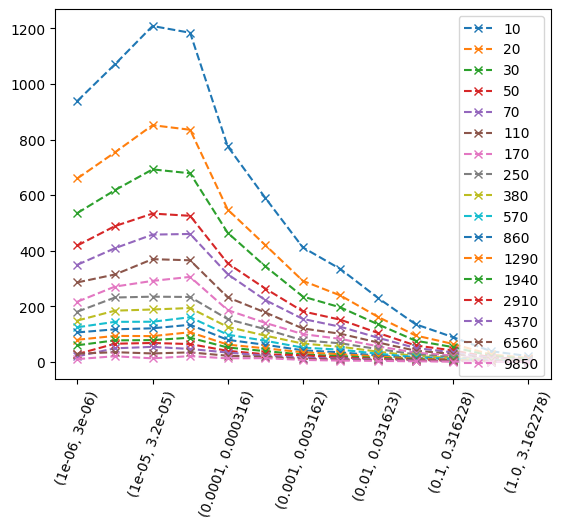

In [75]:
pd.DataFrame(statistics).plot(marker="x",linestyle="--")
xticks = plt.xticks(rotation=70)

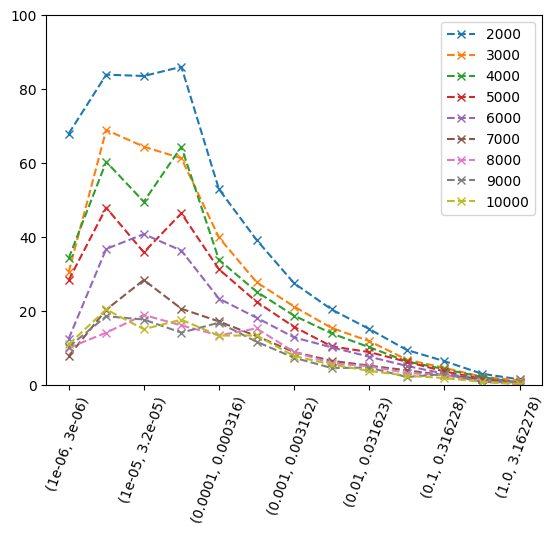

In [76]:
pd.DataFrame(statistics_higher_res).plot(marker="x",linestyle="--",ylim=[0,100])
xticks = plt.xticks(rotation=70)